# Inverse pricing: recover volatility from synthetic option prices

An inverse problem chooses model parameters so that model prices match observed
prices. We first recover one constant volatility, then calibrate a two-parameter
**local-volatility function** through the finite-difference engine.

All quotes are synthetic, noise-free European call prices in dollars. This is a
controlled optimization demonstration, not a claim that sparse market prices
uniquely determine a volatility surface. Run all cells with an installed
QuantLibTorch package and CPU PyTorch `float64`.

Both exercises use valuation 2025-01-01, expiry 2026-01-01, Actual/365 Fixed
and continuously compounded risk-free rate 3% and dividend yield 1%.

In [1]:
import math
import torch
import matplotlib.pyplot as plt
from quantlibtorch import analytic_european, fd_vanilla

torch.set_num_threads(1)
DTYPE = torch.float64
strikes = [90., 100., 110.]
def constant_prices(sigma):
    return torch.stack([analytic_european(sigma, strike=k, spot=100., rate=.03,
                                        dividend_yield=.01) for k in strikes])
true_sigma = torch.tensor(.24, dtype=DTYPE)
with torch.no_grad():
    quotes = constant_prices(true_sigma)
raw_sigma = torch.nn.Parameter(torch.tensor(math.log(math.expm1(.14)), dtype=DTYPE))
optimizer = torch.optim.LBFGS([raw_sigma], lr=1., max_iter=20,
                            tolerance_grad=1e-10, tolerance_change=1e-13,
                            line_search_fn="strong_wolfe")
constant_history = []
def constant_closure():
    optimizer.zero_grad(set_to_none=True)
    sigma = torch.nn.functional.softplus(raw_sigma)
    loss = (constant_prices(sigma)-quotes).square().mean()
    loss.backward()
    constant_history.append(loss.item())
    return loss
optimizer.step(constant_closure)
recovered_sigma = torch.nn.functional.softplus(raw_sigma).detach()
assert abs(recovered_sigma.item()-.24) < 1e-6
print(f"True volatility: {true_sigma.item():.8f}; recovered: {recovered_sigma.item():.8f}")
print("Strike / target / fitted")
with torch.no_grad():
    for k, target, fitted in zip(strikes, quotes, constant_prices(recovered_sigma)):
        print(f"{k:6.1f} / {target.item():.6f} / {fitted.item():.6f}")

True volatility: 0.24000000; recovered: 0.24000000
Strike / target / fitted
  90.0 / 15.911561 / 15.911560
 100.0 / 10.375567 / 10.375567
 110.0 / 6.431748 / 6.431748


This fits a shared constant Black--Scholes volatility to three prices. Inverting
one price for its own scalar Black--Scholes volatility is **implied-volatility
inversion**. Repeating that inversion across contracts gives an implied-volatility
surface; it does not directly give the local diffusion coefficient
$\sigma_{\mathrm{loc}}(t,S)$.

## Calibrate a local-volatility function

Under the risk-neutral measure,
$dS_t=(r-q)S_t\,dt+\sigma_{\mathrm{loc}}(S_t)S_t\,dW_t^{\mathbb Q}$.
We choose a small two-parameter teaching parameterization,

$$\sigma_{\mathrm{loc}}(S;a,b)=0.08+0.30\,
\operatorname{sigmoid}\{a+b\tanh[2\log(S/100)]\}.$$

The level $a$ and slope $b$ are unknown. A fixed grid of log-spot samples is sent
to `fd_vanilla`; QuantLibTorch interpolates samples in log spot, with flat
extrapolation. Sampling and interpolation are part of the implemented model.
The PDE mesh is distinct from this coefficient sampling grid, and stays fixed
during calibration.

In [2]:
sample_spots = torch.tensor([40., 60., 80., 100., 125., 165., 250.], dtype=DTYPE)
log_spots = sample_spots.log().tolist()
feature = 2*(sample_spots/100.).log()
local_strikes = [80., 90., 100., 110., 120.]
def surface(parameters):
    a, b = parameters.unbind()
    return (.08+.30*torch.sigmoid(a+b*feature.tanh())).reshape(1, -1)
def local_prices(parameters):
    vol = surface(parameters)
    return torch.stack([fd_vanilla(vol, times=[0.], log_spots=log_spots,
        spot=100., strike=k, rate=.03, dividend_yield=.01, mode="adjoint",
        time_steps=30, grid_points=61, damping_steps=2, mesh_volatility=.22)
        for k in local_strikes])
truth = torch.tensor([-.3, .7], dtype=DTYPE)
with torch.no_grad():
    local_quotes = local_prices(truth)
parameters = torch.nn.Parameter(torch.tensor([.3, -.2], dtype=DTYPE))
local_optimizer = torch.optim.LBFGS([parameters], max_iter=25,
    tolerance_grad=1e-9, tolerance_change=1e-13, line_search_fn="strong_wolfe")
local_history = []
def local_closure():
    local_optimizer.zero_grad(set_to_none=True)
    loss = (local_prices(parameters)-local_quotes).square().mean()
    loss.backward()
    assert parameters.grad is not None and torch.isfinite(parameters.grad).all()
    local_history.append(loss.item())
    return loss
local_optimizer.step(local_closure)
with torch.no_grad():
    fitted_quotes = local_prices(parameters)
    local_rmse = (fitted_quotes-local_quotes).square().mean().sqrt().item()
assert local_rmse < 1e-5
assert torch.max(torch.abs(parameters.detach()-truth)).item() < 1e-3
print(f"True [level, slope]: {truth.tolist()}")
print(f"Recovered: {parameters.detach().tolist()}; price RMSE: {local_rmse:.3g} dollars")

True [level, slope]: [-0.3, 0.7]
Recovered: [-0.29999993140384446, 0.6999999764140045]; price RMSE: 1.6e-07 dollars


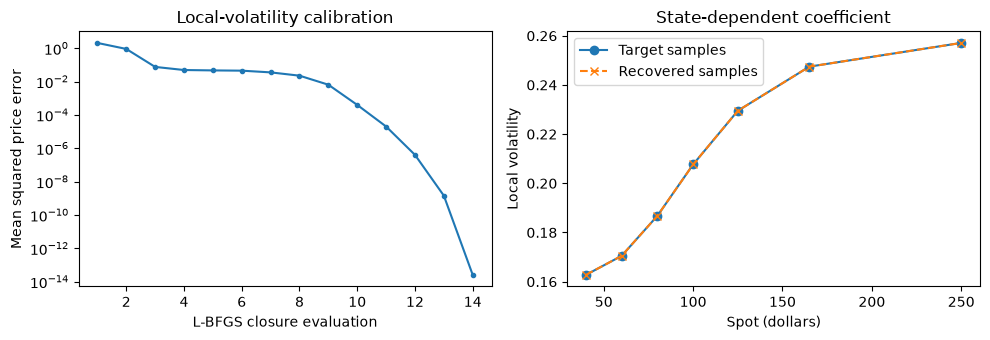

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].semilogy(range(1, len(local_history)+1), local_history, marker=".")
axes[0].set(xlabel="L-BFGS closure evaluation", ylabel="Mean squared price error",
            title="Local-volatility calibration")
axes[1].plot(sample_spots, surface(truth).flatten(), "o-", label="Target samples")
axes[1].plot(sample_spots, surface(parameters).detach().flatten(), "x--", label="Recovered samples")
axes[1].set(xlabel="Spot (dollars)", ylabel="Local volatility", title="State-dependent coefficient")
axes[1].legend()
fig.tight_layout()
plt.show()
RESULT = {"true_sigma": true_sigma.item(), "recovered_sigma": recovered_sigma.item(),
          "true_local_parameters": truth.tolist(), "recovered_local_parameters": parameters.detach().tolist(),
          "local_price_rmse": local_rmse, "local_closure_evaluations": len(local_history)}

The local-volatility targets and fit use the same discretization on purpose:
parameter recovery tests the inverse workflow without introducing an unknown
discretization bias. It is not an independent validation of continuous-model
accuracy. In applications, use separate held-out prices, mesh/domain refinement,
quote uncertainty weights and regularization. L-BFGS may evaluate a trial point
several times per iteration; the horizontal axis above counts those evaluations.

The analytic problem uses full AD. The PDE fit uses first-order discrete
adjoints, which are sufficient for this optimizer. Use full AD when the loss
requires derivatives of Greeks; adjoint mode rejects higher derivatives.